In [8]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os

In [9]:
def read_files(glob_pattern, minyear=0, maxyear=9999):
    files = glob.glob(glob_pattern)
    open_areas = []
    for fname in tqdm(files):
        year = int(os.path.basename(fname)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue
            
        hdf = h5py.File(fname)
        
        if 'open_fraction_by_sample' in hdf.keys():
            open_areas.append(hdf['open_fraction_by_sample'][()].item())
        else:
            open_areas.append(hdf['open_fraction_by_realization'][0])

    return open_areas

In [10]:
open_areas_samples = read_files('../data/validation/open_area_samples/*.hdf5')

100%|█████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1959.84it/s]


In [11]:
open_areas_testdata = read_files('../data/validation.first_cut/open_area_testdata/*.hdf5')

100%|███████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 1991.50it/s]


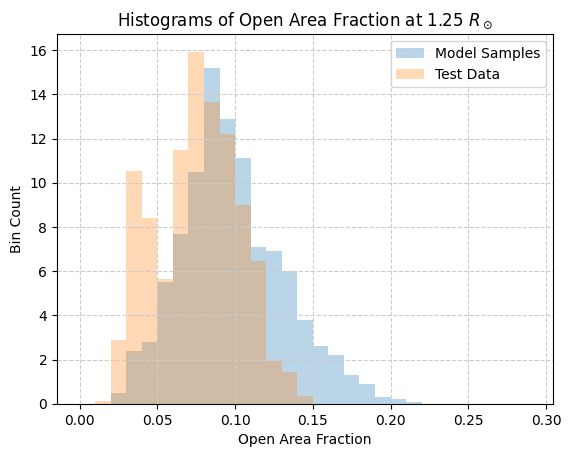

In [12]:
bins = np.arange(0, .3, .01)


plt.hist(open_areas_samples, bins=bins, label='Model Samples', alpha=0.3, density=True)
plt.hist(open_areas_testdata, bins=bins, label='Test Data', alpha=0.3, density=True)

plt.legend()
plt.ylabel('Bin Count')
plt.xlabel('Open Area Fraction')
plt.title(r'Histograms of Open Area Fraction at 1.25 $R_\odot$')
plt.grid(linestyle='dashed', color='#ccc')
plt.savefig('../plots/paper/openarea.png', dpi=300)

In [13]:
print('Samples')
print('---------')
print('Mean %.3f' % np.mean(open_areas_samples))
print('STD %.3f' % np.std(open_areas_samples))
print()
print('Test Data')
print('---------')
print('Mean %.3f' % np.mean(open_areas_testdata))
print('STD %.3f' % np.std(open_areas_testdata))
print()

Samples
---------
Mean 0.098
STD 0.033

Test Data
---------
Mean 0.076
STD 0.027

